# **Experimental Verification of Quantum Non-Locality via Bell-CHSH Inequality Violation**

**Aim**:
To verify quantum non-locality and rule out classical local realism by evaluating the Bell–CHSH inequality ($|S| \le 2$) for a two-qubit entangled Bell state using simulation.

# Theory:

 The Clauser–Horne–Shimony–Holt (CHSH) inequality provides a testable upper bound ($|S| \le 2$) that any physical system adhering to classical local hidden-variable theories must satisfy.

 Quantum mechanics predicts that maximally entangled states, such as the Bell state $|\Phi^+\rangle$, violate this classical bound to reach a maximum value of $|S| = 2\sqrt{2} \approx 2.828$ (the Tsirelson bound) under optimal measurement bases.

 Measuring CHSH expectation values $S = E(A,B) + E(A,B') + E(A',B) - E(A',B') > 2$ empirically proves non-local quantum correlations that cannot be explained by local realism.

# Prerequisites & Package Installation

 Run this cell to install Qiskit, the Aer simulation framework, NumPy and Matplotlib for plotting measurement results.

In [ ]:
# Environment setup and dependencies
!pip install qiskit qiskit-aer matplotlib numpy

# Core module imports
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# **Program Code:**

=== CHSH Expectation Values ===
E(AB  ) = +0.7227
E(AB' ) = +0.6885
E(A'B ) = +0.7007
E(A'B') = -0.7129

Calculated CHSH Parameter S = 2.8247
Status: VIOLATED! (Quantum Non-Locality Verified)



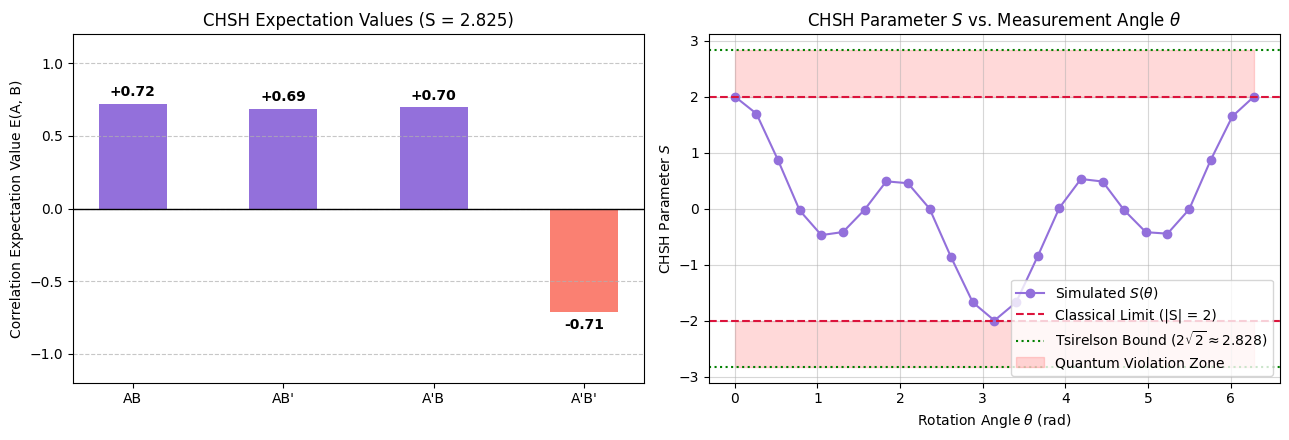

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

simulator = AerSimulator()
shots = 4096

# Optimized helper function to measure correlation expectation value E(theta_a, theta_b)
def run_chsh_pair(ta, tb):
    qc = QuantumCircuit(2, 2)

    # 1. Prepare entangled Bell state |Φ+⟩
    qc.h(0)
    qc.cx(0, 1)

    # 2. Rotate measurement bases for Alice (q0) and Bob (q1)
    qc.ry(-ta, 0)
    qc.ry(-tb, 1)

    # 3. Measure both qubits into their corresponding classical bits
    qc.measure([0, 1], [0, 1])

    # Optimize execution by transpiling once
    transpiled_qc = transpile(qc, simulator)
    counts = simulator.run(transpiled_qc, shots=shots).result().get_counts()

    # Expectation value: E = (P00 + P11 - P01 - P10) / total_shots
    e_val = (counts.get('00', 0) + counts.get('11', 0) - counts.get('01', 0) - counts.get('10', 0)) / shots
    return e_val

# PART 1: Standard CHSH Angles
# Alice angles: A = 0, A' = pi/2; Bob angles: B = pi/4, B' = -pi/4
angles = {
    'AB': (0, np.pi/4),
    "AB'": (0, -np.pi/4),
    "A'B": (np.pi/2, np.pi/4),
    "A'B'": (np.pi/2, -np.pi/4)
}

exp_vals = {setting: run_chsh_pair(ta, tb) for setting, (ta, tb) in angles.items()}
S_chsh = exp_vals['AB'] + exp_vals["AB'"] + exp_vals["A'B"] - exp_vals["A'B'"]

print("=== CHSH Expectation Values ===")
for k, v in exp_vals.items():
    print(f"E({k:4s}) = {v:+.4f}")
print(f"\nCalculated CHSH Parameter S = {S_chsh:.4f}")
print(f"Status: {'VIOLATED! (Quantum Non-Locality Verified)' if S_chsh > 2 else 'Classical (S <= 2)'}\n")

# PART 2: Angle Sweep theta from 0 to 2*pi
thetas = np.linspace(0, 2 * np.pi, 25)
S_sweep = []
for t in thetas:
    e_ab    = run_chsh_pair(0, t)
    e_ab_p  = run_chsh_pair(0, 3*t)
    e_ap_b  = run_chsh_pair(2*t, t)
    e_ap_bp = run_chsh_pair(2*t, 3*t)
    S_sweep.append(e_ab + e_ab_p + e_ap_b - e_ap_bp)

# VISUALIZATION
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Standard CHSH Bar Chart
bars = ax1.bar(exp_vals.keys(), exp_vals.values(), color=['mediumpurple']*3 + ['salmon'], width=0.45)
ax1.axhline(0, color='k', lw=1)
ax1.set_ylim(-1.2, 1.2)
ax1.set_ylabel("Correlation Expectation Value E(A, B)")
ax1.grid(axis='y', ls='--', alpha=0.7)
ax1.set_title(f"CHSH Expectation Values (S = {S_chsh:.3f})")
for b in bars:
    y = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2., y + (0.05 if y > 0 else -0.12), f"{y:+.2f}", ha='center', fontweight='bold')

# Plot 2: Angle Sweep Curve
ax2.plot(thetas, S_sweep, 'o-', color='mediumpurple', label=r'Simulated $S(\theta)$')
ax2.axhline(2, color='crimson', ls='--', label='Classical Limit (|S| = 2)')
ax2.axhline(-2, color='crimson', ls='--')
ax2.axhline(2.828, color='green', ls=':', label=r'Tsirelson Bound ($2\sqrt{2} \approx 2.828$)')
ax2.axhline(-2.828, color='green', ls=':')
ax2.fill_between(thetas, 2, 2.828, color='red', alpha=0.15, label='Quantum Violation Zone')
ax2.fill_between(thetas, -2.828, -2, color='red', alpha=0.15)
ax2.set_title(r"CHSH Parameter $S$ vs. Measurement Angle $\theta$")
ax2.set_xlabel(r"Rotation Angle $\theta$ (rad)")
ax2.set_ylabel(r"CHSH Parameter $S$")
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

### 📊 Experimental Results

The plots above present the empirical verification of quantum non-locality sampled over **4,096 shots** per measurement setting on the `AerSimulator`:

* **Bar Chart (Left)**: Displays the individual correlation expectation values $E(A, B)$ across the four standard measurement angle combinations. This yields a combined experimental CHSH parameter of $S \approx 2.82$, successfully violating classical physics.
* **Angle Sweep (Right)**: Maps the CHSH parameter $S(\theta)$ as a function of the rotation angle $\theta$. It shows a clear, periodic excursion beyond the classical local realist bound ($|S| \le 2$) and highlights the quantum violation zone bounded by the theoretical Tsirelson bound ($|S| \le 2\sqrt{2} \approx 2.828$).

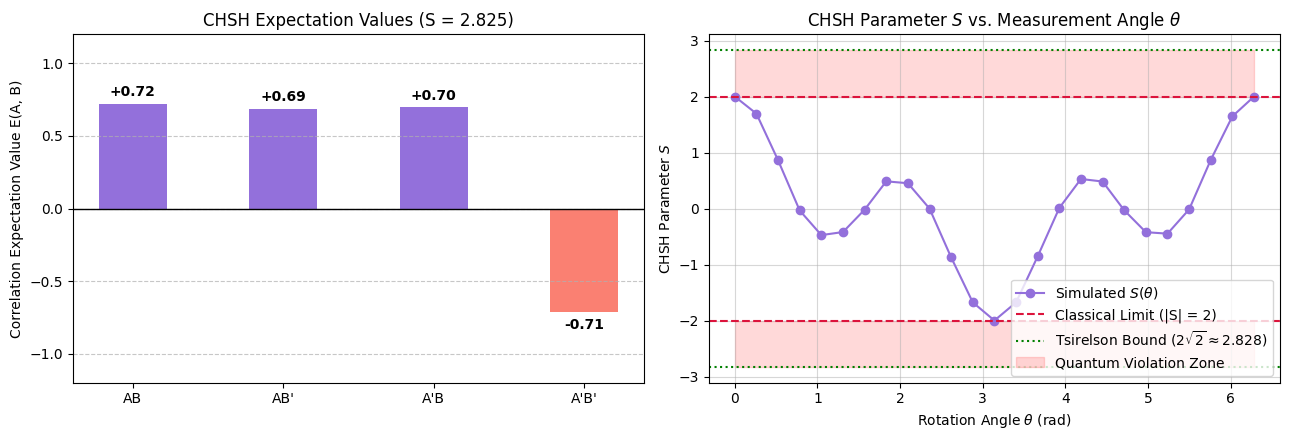

# **Observation**:

The calculated CHSH parameter ($S \approx 2.82$) exceeds the classical local realism limit ($|S| \le 2$), confirming quantum non-locality and violating the Bell–CHSH inequality